# 2026-07-10 DNA Quantification — Standard Curve (Portelite BDR / Qubit)

Same assay/method as [`0622_quantification.ipynb`](0622_quantification.ipynb) and
[`0629_quantification.ipynb`](0629_quantification.ipynb): a fresh standard series is read this
session, fit by **linear regression of RFU vs. concentration (ng/µL)**, then each sample reading
is inverted on the fitted line.

**Kit:** Portelite™ Fluorimetric DNA Quantitation Kit, Broad Dynamic Range (AAT Bioquest 17665),
Ex/Em 480/530 nm, green channel.

**Samples:** two strains (**9-2-1**, **9-6-2**), each with three variants (`r1/r2/r3`) picked from
different plates — i.e. distinct mutations/variants of the same strain, six separate genomic DNA
extracts.

**Three sections:** (1) build the standard curve, (2) convert each reading to ng/µL,
(3) DNA mass per tube.

## Session notes (2026-07-10) — read before trusting any number
- **4-point curve, no blank read this session.** Standards were **S1, S3, S10, S30** only — no
  Std-0 blank and no S100 top standard. So there is **no blank subtraction**; the fitted intercept
  absorbs the background (`BLANK_RFU = 0`). Top standard is **30 ng/µL**.
- **⚠ Every sample reads above the top standard.** The lowest (`9-2-1_r1`, 2378 RFU) is ~1.7× the
  S30 reading (1369.67 RFU); the highest (`9-6-2_r2`, 47704 RFU) is ~35×. **All six values are
  extrapolated** far beyond the curve, which is already curving upward — the quoted ng/µL are
  order-of-magnitude estimates only. For real numbers: **dilute the samples and re-read**, or read
  a higher standard (S100).
- **`r1/r2/r3` are distinct variants, not replicates.** Different plates → different mutations of
  the same strain, each its own tube. So they are **not averaged**, and their masses are
  **additive** (6 separate extracts).
- **Remaining volume = 90 µL per tube** (`VOL_REMAINING_uL`, top cell), the same-protocol
  9-2-1/9-6-2 genomic-extract volume recorded in 0605/0608/0622 and
  `data/dna_extraction_inventory.md`. Adjust if these variant preps were eluted differently.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# ---- Tunable assay parameters -------------------------------------------------
DILUTION_FACTOR = 1          # multiply curve-derived conc by this if samples were pre-diluted
# Remaining eluate per tube (uL). 9-2-1 / 9-6-2 bacteria-genome extracts (Round 1, extracted
# 2026-06-05) are recorded at ~90 uL remaining in 0605/0608/0622 and
# data/dna_extraction_inventory.md (appendix L159 + L214-215). Assumes today's samples are those
# bacterial extracts, NOT the phage picks (9-2-1 Φ8 / 9-6-2 Φ8), whose lysate volume is unrecorded.
VOL_REMAINING_uL = 90.0
DATE = '2026-07-10'
OUTPUT_DIR = 'output/0710_quantification'   # figures saved here, named by date + content
os.makedirs(OUTPUT_DIR, exist_ok=True)
# -------------------------------------------------------------------------------

## Section 1 — Build the standard curve

No Std-0 blank was read this session, so there is **no blank subtraction** (`BLANK_RFU = 0`); the
4 points (S1, S3, S10, S30) are fit directly as `RFU = slope · conc + intercept` by linear
regression, and the fitted intercept absorbs the background. Report slope, intercept and R².

In [2]:
# Standards (ng/uL, raw green-channel RFU) -- read 2026-07-10.
# 4-point series this session: S1, S3, S10, S30 (no Std-0 blank, no S100).
standards = pd.DataFrame({
    'standard':   ['Std 1', 'Std 3', 'Std 10', 'Std 30'],
    'conc_ng_uL': [1.0, 3.0, 10.0, 30.0],
    'rfu':        [210.50, 308.30, 485.05, 1369.67],
})

# No blank read this session -> no blank subtraction; fitted intercept absorbs background.
BLANK_RFU = 0.0
standards['rfu_corrected'] = standards['rfu'] - BLANK_RFU

# Linear regression: rfu_corrected = slope * conc + intercept
slope, intercept = np.polyfit(standards['conc_ng_uL'], standards['rfu_corrected'], 1)
fit = slope * standards['conc_ng_uL'] + intercept
ss_res = np.sum((standards['rfu_corrected'] - fit) ** 2)
ss_tot = np.sum((standards['rfu_corrected'] - standards['rfu_corrected'].mean()) ** 2)
r_squared = 1 - ss_res / ss_tot

MAX_STD_CONC = standards['conc_ng_uL'].max()  # 30 ng/uL -> above this = extrapolated

print(f'Blank (Std 0) RFU      : {BLANK_RFU:.2f}  (no blank read this session)')
print(f'Slope                  : {slope:.4f} RFU per ng/uL')
print(f'Intercept              : {intercept:.4f} RFU')
print(f'R^2                    : {r_squared:.6f}')
print(f'Top standard           : {MAX_STD_CONC:.0f} ng/uL '
      f'(readings above this are extrapolated)')
standards

Blank (Std 0) RFU      : 0.00  (no blank read this session)
Slope                  : 39.8617 RFU per ng/uL
Intercept              : 154.9008 RFU
R^2                    : 0.992357
Top standard           : 30 ng/uL (readings above this are extrapolated)


,standard,conc_ng_uL,rfu,rfu_corrected
0,Std 1,1.0,210.50,210.50
1,Std 3,3.0,308.30,308.30
2,Std 10,10.0,485.05,485.05
3,Std 30,30.0,1369.67,1369.67


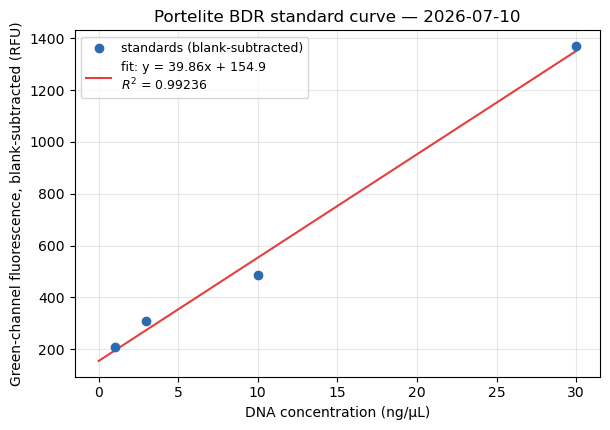

In [3]:
# Conversion helper used by Section 2: invert the fitted line, apply dilution factor.
def rfu_to_conc(rfu):
    """Raw green-channel RFU -> DNA concentration (ng/uL) in the original tube."""
    return (np.asarray(rfu, dtype=float) - BLANK_RFU - intercept) / slope * DILUTION_FACTOR

# Plot the standard curve with the fit
fig, ax = plt.subplots(figsize=(6.2, 4.4))
ax.scatter(standards['conc_ng_uL'], standards['rfu_corrected'],
           color='#2b6cb0', zorder=3, label='standards (blank-subtracted)')
xline = np.linspace(0, MAX_STD_CONC, 100)
ax.plot(xline, slope * xline + intercept, color='#e53e3e', lw=1.5,
        label=f'fit: y = {slope:.2f}x + {intercept:.1f}\n$R^2$ = {r_squared:.5f}')
ax.set_xlabel('DNA concentration (ng/µL)')
ax.set_ylabel('Green-channel fluorescence, blank-subtracted (RFU)')
ax.set_title('Portelite BDR standard curve — 2026-07-10')
ax.legend(loc='upper left', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'{DATE}_standard-curve.png'),
            dpi=150, bbox_inches='tight')
plt.show()

## Section 2 — Sample DNA concentrations

Convert each raw reading to ng/µL via the fitted curve. `extrapolated = True` flags any sample
above the top standard.

In [4]:
# Raw green-channel readings, 2026-07-10. Two strains (9-2-1, 9-6-2), each with 3 variants
# (r1/r2/r3) picked from DIFFERENT PLATES -> distinct mutations/variants of the same strain.
# Each is its own tube: NOT averaged, and their masses are additive (6 separate extracts).
samples = pd.DataFrame([
    ('9-2-1_r1',  2378.22),
    ('9-2-1_r2', 18378.32),
    ('9-2-1_r3',  3399.31),
    ('9-6-2_r1',  5123.33),
    ('9-6-2_r2', 47703.89),
    ('9-6-2_r3', 10563.26),
], columns=['sample', 'rfu'])
samples['strain'] = samples['sample'].str.split('_').str[0]   # 9-2-1 / 9-6-2 (variants share a strain)

samples['conc_ng_uL'] = rfu_to_conc(samples['rfu'])
samples['extrapolated'] = samples['conc_ng_uL'] > MAX_STD_CONC

with pd.option_context('display.float_format', lambda v: f'{v:,.2f}'):
    print(samples[['sample', 'strain', 'rfu', 'conc_ng_uL', 'extrapolated']].to_string(index=False))
print(f"\nSamples above the {MAX_STD_CONC:.0f} ng/uL top standard (extrapolated): "
      f"{int(samples['extrapolated'].sum())} of {len(samples)}")
print("NOTE: all reads are extrapolated well beyond the 30 ng/uL top standard -> "
      "concentrations are order-of-magnitude estimates; dilute & re-read for real values.")

  sample strain       rfu  conc_ng_uL  extrapolated
9-2-1_r1  9-2-1  2,378.22       55.78          True
9-2-1_r2  9-2-1 18,378.32      457.17          True
9-2-1_r3  9-2-1  3,399.31       81.39          True
9-6-2_r1  9-6-2  5,123.33      124.64          True
9-6-2_r2  9-6-2 47,703.89    1,192.85          True
9-6-2_r3  9-6-2 10,563.26      261.11          True

Samples above the 30 ng/uL top standard (extrapolated): 6 of 6
NOTE: all reads are extrapolated well beyond the 30 ng/uL top standard -> concentrations are order-of-magnitude estimates; dilute & re-read for real values.


### Section 2 plots — concentration per sample, and samples on the curve

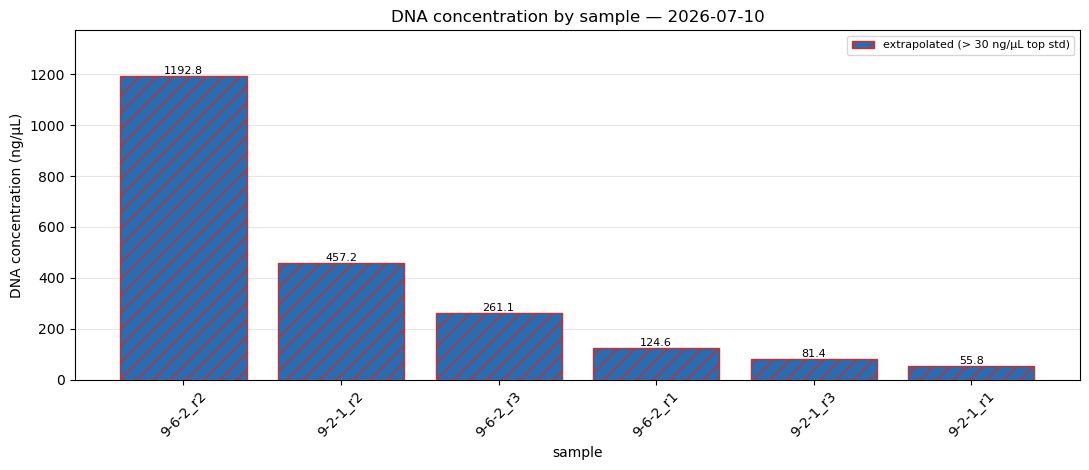

In [5]:
# Bar chart: DNA concentration per sample (sorted high -> low), extrapolated bars hatched.
from matplotlib.patches import Patch

df = samples.sort_values('conc_ng_uL', ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 4.8))
bars = ax.bar(df['sample'], df['conc_ng_uL'], color='#2b6cb0', zorder=3)
for bar, extrap in zip(bars, df['extrapolated']):
    if extrap:
        bar.set_hatch('//'); bar.set_edgecolor('#c53030')
for bar, val in zip(bars, df['conc_ng_uL']):
    ax.text(bar.get_x() + bar.get_width() / 2, val, f'{val:.1f}',
            ha='center', va='bottom', fontsize=8)
ax.set_ylabel('DNA concentration (ng/µL)')
ax.set_xlabel('sample')
ax.set_title('DNA concentration by sample — 2026-07-10')
ax.tick_params(axis='x', rotation=45)
ax.margins(y=0.15); ax.grid(axis='y', alpha=0.3)
if samples['extrapolated'].any():
    ax.legend(handles=[Patch(facecolor='#2b6cb0', hatch='//', edgecolor='#c53030',
                             label=f'extrapolated (> {MAX_STD_CONC:.0f} ng/µL top std)')],
              fontsize=8, loc='upper right')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'{DATE}_concentration-by-sample.png'),
            dpi=150, bbox_inches='tight')
plt.show()

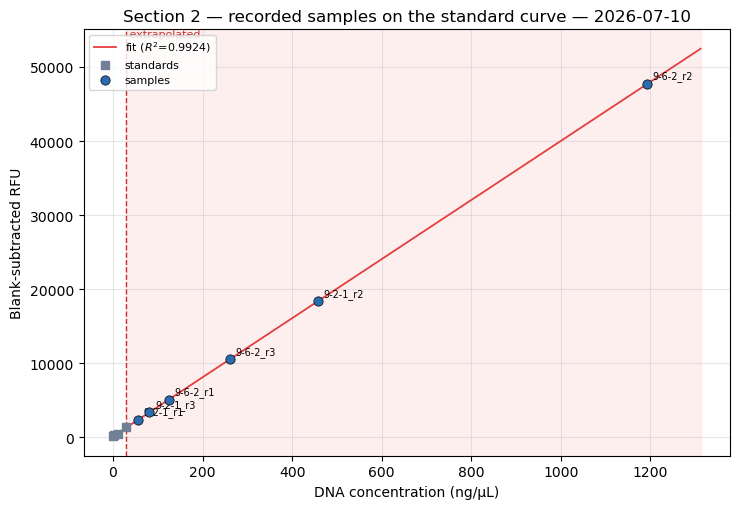

In [6]:
# Place each recorded sample on the standard curve at (conc, blank-subtracted RFU).
fig, ax = plt.subplots(figsize=(7.5, 5.2))
xmax = max(samples['conc_ng_uL'].max() * 1.10, MAX_STD_CONC)
xs = np.linspace(0, xmax, 100)
ax.plot(xs, slope * xs + intercept, color='#e53e3e', lw=1.3, zorder=2,
        label=f'fit ($R^2$={r_squared:.4f})')
ax.scatter(standards['conc_ng_uL'], standards['rfu_corrected'], color='#718096',
           marker='s', s=40, zorder=3, label='standards')
ax.scatter(samples['conc_ng_uL'], samples['rfu'] - BLANK_RFU, color='#2b6cb0', s=45,
           zorder=4, edgecolor='black', linewidth=0.5, label='samples')
for _, r in samples.iterrows():
    ax.annotate(r['sample'], (r['conc_ng_uL'], r['rfu'] - BLANK_RFU),
                textcoords='offset points', xytext=(4, 4), fontsize=7)
if xmax > MAX_STD_CONC:
    ax.axvspan(MAX_STD_CONC, xmax, color='#fed7d7', alpha=0.4, zorder=1)
    ax.axvline(MAX_STD_CONC, color='#c53030', ls='--', lw=1, zorder=2)
    ax.text(MAX_STD_CONC, ax.get_ylim()[1], ' extrapolated', color='#c53030',
            fontsize=8, va='top', ha='left')
ax.set_xlabel('DNA concentration (ng/µL)')
ax.set_ylabel('Blank-subtracted RFU')
ax.set_title('Section 2 — recorded samples on the standard curve — 2026-07-10')
ax.legend(fontsize=8, loc='upper left'); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'{DATE}_samples-on-standard-curve.png'),
            dpi=150, bbox_inches='tight')
plt.show()

## Section 3 — DNA mass currently in each tube

`mass = concentration (ng/µL) × remaining volume (µL)`, reported in µg. `VOL_REMAINING_uL = 90 µL`
per tube (same-protocol extract volume, per the 9-2-1/9-6-2 records — see top cell).

`r1/r2/r3` are **different plates = distinct variants of the same strain**, so each is its own
tube: masses are **additive** within a strain and overall (per-strain subtotals + grand total
below). Caveat: concentrations are **extrapolated** past the curve, so all µg figures are
order-of-magnitude only.

In [7]:
samples['remaining_vol_uL'] = VOL_REMAINING_uL
samples['mass_ug'] = samples['conc_ng_uL'] * samples['remaining_vol_uL'] / 1000.0

with pd.option_context('display.float_format', lambda v: f'{v:,.3f}'):
    print(samples[['sample', 'strain', 'conc_ng_uL', 'remaining_vol_uL', 'mass_ug', 'extrapolated']]
          .to_string(index=False))

# Each variant is its own tube, so masses are additive within a strain and overall.
print('\nPer-strain subtotal (sum of its 3 variants):')
with pd.option_context('display.float_format', lambda v: f'{v:,.3f}'):
    print(samples.groupby('strain')['mass_ug'].sum().to_string())

print(f"\nTotal DNA across all {len(samples)} variant tubes (at {VOL_REMAINING_uL:.0f} uL each): "
      f"{samples['mass_ug'].sum():,.2f} ug")
print(f"Mean concentration: {samples['conc_ng_uL'].mean():,.2f} ng/uL  "
      f"(range {samples['conc_ng_uL'].min():,.2f} - {samples['conc_ng_uL'].max():,.2f})")

samples.to_csv(os.path.join(OUTPUT_DIR, f'{DATE}_quantification.csv'), index=False)
print(f"saved -> {os.path.join(OUTPUT_DIR, f'{DATE}_quantification.csv')}")

  sample strain  conc_ng_uL  remaining_vol_uL  mass_ug  extrapolated
9-2-1_r1  9-2-1      55.776            90.000    5.020          True
9-2-1_r2  9-2-1     457.166            90.000   41.145          True
9-2-1_r3  9-2-1      81.392            90.000    7.325          True
9-6-2_r1  9-6-2     124.642            90.000   11.218          True
9-6-2_r2  9-6-2   1,192.848            90.000  107.356          True
9-6-2_r3  9-6-2     261.111            90.000   23.500          True

Per-strain subtotal (sum of its 3 variants):
strain
9-2-1    53.490
9-6-2   142.074

Total DNA across all 6 variant tubes (at 90 uL each): 195.56 ug
Mean concentration: 362.16 ng/uL  (range 55.78 - 1,192.85)
saved -> output/0710_quantification/2026-07-10_quantification.csv


## Readout

- **Curve:** 4-point S1–S30 series, no blank. Linear fit `RFU = 39.86·conc + 154.90`,
  **R² = 0.9924**. The fit is anchored almost entirely by the S30 point — S1/S3/S10 span only
  ~210–485 RFU — so low-end precision is weak and the "good" R² is partly leverage.
- **Variants (all extrapolated > 30 ng/µL top standard):**
  - **9-2-1** — r1 ≈ **55.8**, r2 ≈ **457.2**, r3 ≈ **81.4** ng/µL
  - **9-6-2** — r1 ≈ **124.6**, r2 ≈ **1192.8**, r3 ≈ **261.1** ng/µL
  - Within each strain the three plate-variants differ ~6–10×, with `r2` the strongest — real
    variant-to-variant differences (different plates), not replicate scatter. **Numbers are
    order-of-magnitude only** (extrapolated). To quantify precisely: dilute into the 1–30 ng/µL
    window and re-read, or add an S100 standard.
- **Mass per tube (90 µL each, additive across the 6 variant tubes):** 9-2-1 variants ≈ 5.0 / 41.1
  / 7.3 µg; 9-6-2 variants ≈ 11.2 / 107.4 / 23.5 µg. Per-strain subtotals + grand total in
  Section 3. All µg values are order-of-magnitude (extrapolated conc).

---
*Log: created 2026-07-10. Structure copied from `0622_quantification.ipynb`. 4-point curve (S1, S3,
S10, S30), no Std-0 blank and no S100, so blank subtraction is off (`BLANK_RFU = 0`). Samples are
two strains (9-2-1, 9-6-2), each with three plate-picked variants (r1/r2/r3) — treated as distinct
tubes (not averaged; masses additive). All six reads fall above the top standard → extrapolated.
Remaining volume 90 µL/tube from the 9-2-1/9-6-2 genomic-extract records (0605/0608/0622 +
`data/dna_extraction_inventory.md`). Outputs in `output/0710_quantification/`.*